# LSTM-Based Energy Consumption Forecasting Pipeline

**Dataset:** `final_training_dataset.csv`  
**Target:** `energy_kwh.1` (hourly kWh consumption)  
**Author:** Senior ML Engineer — Time-Series Forecasting

---

## Architecture Summary

```
Input → Feature Engineering → MinMax Scaling → Sliding-Window Sequences
      → Stacked Bi-LSTM + Dropout + BatchNorm → Dense Head → Prediction
      → Inverse Transform → MAE / RMSE / R² Evaluation → Visualisations
```

### Pipeline Steps
1. **Data Loading & Preprocessing** — parse timestamps, interpolate missing values
2. **Feature Engineering** — lag features, rolling stats, cyclic calendar encoding
3. **Scaling** — MinMaxScaler fitted only on train data (no leakage)
4. **Sequence Creation** — sliding-window supervised format
5. **Model Building** — Stacked Bi-LSTM with Bahdanau attention
6. **Training** — EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
7. **Evaluation** — MAE, RMSE, R², MAPE
8. **Visualisation** — 4-panel diagnostic figure

## Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")           # headless – safe in any environment
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, Bidirectional, Dense, Dropout,
    BatchNormalization, LayerNormalization, Multiply, Activation,
    Flatten, Permute, RepeatVector, Lambda
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import tensorflow.keras.backend as K

print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")

TensorFlow version: 2.21.0
NumPy version: 2.1.3


## Global Hyperparameters

All configuration in one place for easy tuning.

In [2]:
CONFIG = {
    # --- Data ---
    "csv_path"       : "../data/processed/final_training_dataset.csv",
    "timestamp_col"  : "timestamp",
    "target_col"     : "energy_kwh.1",

    # --- Sequence ---
    "n_steps"        : 24,      # look-back window  (24 h = 1 day)
    "train_ratio"    : 0.80,    # chronological train / test split

    # --- Architecture ---
    "lstm_units"     : [128, 64],   # units per LSTM layer (stacked)
    "dense_units"    : [64, 32],    # units per Dense layer
    "dropout_rate"   : 0.20,
    "use_bidirectional": True,      # wrap LSTM with Bidirectional
    "use_attention"  : True,        # Bahdanau-style self-attention

    # --- Training ---
    "batch_size"     : 32,
    "epochs"         : 150,
    "learning_rate"  : 1e-3,
    "val_split"      : 0.15,        # fraction of train used for validation

    # --- Callbacks ---
    "es_patience"    : 15,
    "lr_patience"    : 7,
    "lr_factor"      : 0.5,
    "lr_min"         : 1e-6,

    # --- Outputs ---
    "model_path"     : "../models/best_lstm_model.keras",
    "plot_path"      : "../outputs/figures/lstm_results.png",
}

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Configuration loaded:")
for k, v in CONFIG.items():
    print(f"  {k:<20}: {v}")

Configuration loaded:
  csv_path            : final_training_dataset.csv
  timestamp_col       : timestamp
  target_col          : energy_kwh.1
  n_steps             : 24
  train_ratio         : 0.8
  lstm_units          : [128, 64]
  dense_units         : [64, 32]
  dropout_rate        : 0.2
  use_bidirectional   : True
  use_attention       : True
  batch_size          : 32
  epochs              : 150
  learning_rate       : 0.001
  val_split           : 0.15
  es_patience         : 15
  lr_patience         : 7
  lr_factor           : 0.5
  lr_min              : 1e-06
  model_path          : best_lstm_model.keras
  plot_path           : lstm_results.png


## Step 1 — Data Loading & Preprocessing

Load CSV, parse timestamps, sort chronologically, and interpolate missing values.

> **Why interpolation over drop?**  
> Time-series data has temporal correlation. A linear interpolation between adjacent hourly readings is far more faithful than deleting rows and creating artificial time gaps.

In [3]:
def load_and_preprocess(cfg: dict) -> tuple[pd.DataFrame, list[str]]:
    """
    Load CSV, parse timestamps, sort chronologically, interpolate
    missing values, and return cleaned DataFrame + feature column list.
    """
    print("=" * 65)
    print("  STEP 1 — LOADING & PREPROCESSING")
    print("=" * 65)

    df = pd.read_csv(cfg["csv_path"])
    print(f"  Raw shape            : {df.shape}")

    # Parse & sort timestamp
    df[cfg["timestamp_col"]] = pd.to_datetime(df[cfg["timestamp_col"]])
    df.sort_values(cfg["timestamp_col"], inplace=True)
    df.set_index(cfg["timestamp_col"], inplace=True)
    df.index.freq = pd.infer_freq(df.index)   # infer hourly freq if regular

    print(f"  Date range           : {df.index.min()}  →  {df.index.max()}")
    print(f"  Rows                 : {len(df):,}")

    # Handle missing values
    missing_before = df.isnull().sum().sum()
    df.interpolate(method="time", inplace=True)       # linear in time
    df.bfill(inplace=True)                            # edge cases at start
    df.ffill(inplace=True)                            # edge cases at end
    missing_after = df.isnull().sum().sum()
    print(f"  Missing values fixed : {missing_before} → {missing_after}")

    # Identify feature columns
    feature_cols = [c for c in df.columns if c != cfg["target_col"]]
    print(f"  Feature columns ({len(feature_cols)}) : {feature_cols}")
    print(f"  Target column        : {cfg['target_col']}")

    return df, feature_cols

In [4]:
df, base_feature_cols = load_and_preprocess(CONFIG)
df.head()

  STEP 1 — LOADING & PREPROCESSING
  Raw shape            : (2136, 23)
  Date range           : 2025-09-20 05:00:00  →  2026-02-26 12:00:00
  Rows                 : 2,136
  Missing values fixed : 7 → 0
  Feature columns (21) : ['temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in']
  Target column        : energy_kwh.1


,energy_kwh.1,temp_hi,bar,dew_in,temp_in,pt_dew,index_thsw,index_uv,hum_out,dose_uv,...,density_in_air,rain,run_wind,emc_in,rate_rain,out_temp,speed_hi,speed_wind,tx_wind,hum_in
timestamp,,,,,,,,,,,,,,,,,,,,,
2025-09-20 05:00:00,276.50,30.375,29.8315,17.625,23.775,26.550,44.775,4.325,80.50,0.4625,...,0.072550,0.0,1.6100,12.6500,0.0,30.275,17.300,6.425,1.0,68.50
2025-09-20 06:00:00,269.25,30.800,29.8005,21.400,25.675,25.975,43.625,3.700,76.00,0.3975,...,0.071625,0.0,2.7175,15.0350,0.0,30.700,19.300,10.900,1.0,77.25
2025-09-20 07:00:00,286.75,30.975,29.7730,22.375,26.600,26.025,42.600,2.650,75.25,0.2825,...,0.071225,0.0,2.6125,15.1750,0.0,30.900,17.700,10.500,1.0,77.75
2025-09-20 08:00:00,228.00,31.300,29.7535,23.400,27.600,26.825,43.000,1.600,77.50,0.1700,...,0.070850,0.0,0.7025,15.2150,0.0,31.250,10.050,2.800,1.0,78.00
2025-09-20 09:00:00,171.75,31.200,29.7310,24.000,28.250,26.875,42.800,1.375,78.25,0.1475,...,0.070525,0.0,0.4000,15.1175,0.0,31.125,6.825,1.600,1.0,77.75


## Step 2 — Feature Engineering

Add time-aware and statistical features to improve model accuracy.

| Feature Type | Rationale |
|---|---|
| **Lag features** | Give the model explicit memory of past values beyond what the LSTM window alone provides |
| **Rolling stats** | Smooth out noise; capture short-term trend & variance |
| **Calendar feats** | Energy has strong daily/weekly periodicity; sin/cos encoding avoids discontinuities |
| **Interaction** | Heat index (temp × humidity) is a known driver of HVAC load and thus energy consumption |

In [5]:
def engineer_features(df: pd.DataFrame, target_col: str) -> pd.DataFrame:
    """
    Add time-aware and statistical features to improve model accuracy.
    """
    print("\n" + "=" * 65)
    print("  STEP 2 — FEATURE ENGINEERING")
    print("=" * 65)

    df = df.copy()

    # Lag features (last 1, 2, 3, 6, 12, 24 h)
    for lag in [1, 2, 3, 6, 12, 24]:
        df[f"energy_lag_{lag}"] = df[target_col].shift(lag)

    # Rolling statistics (3 h, 6 h, 24 h windows)
    for w in [3, 6, 24]:
        df[f"energy_roll_mean_{w}"] = (
            df[target_col].shift(1).rolling(w).mean()
        )
        df[f"energy_roll_std_{w}"] = (
            df[target_col].shift(1).rolling(w).std()
        )

    # Cyclic calendar encoding
    hour  = df.index.hour
    dow   = df.index.dayofweek
    month = df.index.month

    df["hour_sin"]  = np.sin(2 * np.pi * hour / 24)
    df["hour_cos"]  = np.cos(2 * np.pi * hour / 24)
    df["dow_sin"]   = np.sin(2 * np.pi * dow  / 7)
    df["dow_cos"]   = np.cos(2 * np.pi * dow  / 7)
    df["month_sin"] = np.sin(2 * np.pi * month / 12)
    df["month_cos"] = np.cos(2 * np.pi * month / 12)

    # Temperature × Humidity interaction (heat-index proxy)
    if "out_temp" in df.columns and "hum_out" in df.columns:
        df["heat_index"] = df["out_temp"] * df["hum_out"] / 100.0

    # Drop rows with NaN introduced by lags/rolling
    df.dropna(inplace=True)

    n_engineered = len(df.columns)
    print(f"  Total features after engineering : {n_engineered}")
    print(f"  Rows remaining after lag drop    : {len(df):,}")

    return df

In [6]:
df = engineer_features(df, CONFIG["target_col"])
print(f"\nEngineered feature columns:")
print(df.columns.tolist())


  STEP 2 — FEATURE ENGINEERING
  Total features after engineering : 41
  Rows remaining after lag drop    : 2,112

Engineered feature columns:
['energy_kwh.1', 'temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in', 'energy_lag_1', 'energy_lag_2', 'energy_lag_3', 'energy_lag_6', 'energy_lag_12', 'energy_lag_24', 'energy_roll_mean_3', 'energy_roll_std_3', 'energy_roll_mean_6', 'energy_roll_std_6', 'energy_roll_mean_24', 'energy_roll_std_24', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'heat_index']


## Step 3 — Scaling

Scalers are fit **only on training data** to prevent data leakage.

In [7]:
def scale_data(
    df: pd.DataFrame,
    feature_cols: list[str],
    target_col: str,
    train_end_idx: int,
) -> tuple[np.ndarray, np.ndarray, MinMaxScaler, MinMaxScaler]:
    """
    Fit scalers ONLY on training data to prevent data leakage.
    Returns scaled X (features) and y (target) arrays.
    """
    print("\n" + "=" * 65)
    print("  STEP 3 — SCALING")
    print("=" * 65)

    X_raw = df[feature_cols].values
    y_raw = df[[target_col]].values

    scaler_X = MinMaxScaler(feature_range=(0, 1))
    scaler_y = MinMaxScaler(feature_range=(0, 1))

    # Fit only on train portion
    scaler_X.fit(X_raw[:train_end_idx])
    scaler_y.fit(y_raw[:train_end_idx])

    X_scaled = scaler_X.transform(X_raw)
    y_scaled = scaler_y.transform(y_raw).flatten()

    print(f"  Features scaled : {X_scaled.shape[1]} columns")
    print(f"  Target range    : [{y_raw.min():.2f}, {y_raw.max():.2f}] kWh")
    print(f"  Scaler fitted on first {train_end_idx:,} rows (train only)")

    return X_scaled, y_scaled, scaler_X, scaler_y

In [8]:
all_feature_cols = [c for c in df.columns if c != CONFIG["target_col"]]
n_total   = len(df)
train_end = int(n_total * CONFIG["train_ratio"])

X_scaled, y_scaled, scaler_X, scaler_y = scale_data(
    df, all_feature_cols, CONFIG["target_col"], train_end
)


  STEP 3 — SCALING
  Features scaled : 40 columns
  Target range    : [10.50, 397.50] kWh
  Scaler fitted on first 1,689 rows (train only)


## Step 4 — Sequence Creation & Train/Test Split

**Sliding-window supervised format:**  
For each time step `t`, the input is `X[t-n_steps : t]` → shape `(n_steps, n_features)`,  
and the label is `y[t]` (next-step energy consumption).

This avoids any look-ahead bias because `y[t]` is only the *next* timestep, never inside the feature window.

In [9]:
def create_sequences(
    X: np.ndarray,
    y: np.ndarray,
    n_steps: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Build sliding-window sequences for supervised learning."""
    Xs, ys = [], []
    for i in range(n_steps, len(X)):
        Xs.append(X[i - n_steps : i])
        ys.append(y[i])
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)


def split_sequences(
    X_seq: np.ndarray,
    y_seq: np.ndarray,
    train_end_idx: int,
    n_steps: int,
) -> tuple:
    """
    Chronological (time-based) train / test split — no shuffling.
    The cut-point is shifted by n_steps to align sequences correctly.
    """
    print("\n" + "=" * 65)
    print("  STEP 4 — SEQUENCE CREATION & TRAIN / TEST SPLIT")
    print("=" * 65)

    split = train_end_idx - n_steps
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    print(f"  Sequence length (n_steps) : {n_steps}")
    print(f"  X_train shape             : {X_train.shape}")
    print(f"  X_test  shape             : {X_test.shape}")
    print(f"  y_train shape             : {y_train.shape}")
    print(f"  y_test  shape             : {y_test.shape}")

    return X_train, X_test, y_train, y_test

In [10]:
X_seq, y_seq = create_sequences(X_scaled, y_scaled, CONFIG["n_steps"])

X_train, X_test, y_train, y_test = split_sequences(
    X_seq, y_seq, train_end, CONFIG["n_steps"]
)


  STEP 4 — SEQUENCE CREATION & TRAIN / TEST SPLIT
  Sequence length (n_steps) : 24
  X_train shape             : (1665, 24, 40)
  X_test  shape             : (423, 24, 40)
  y_train shape             : (1665,)
  y_test  shape             : (423,)


## Step 5 — Attention Mechanism

**Bahdanau-style additive self-attention** over the LSTM time steps.

> The model learns to *weight* which past timesteps matter most for the current prediction — e.g., peak-load hours from yesterday may be more relevant than low-load hours 20 steps back. This makes the representation richer than simply taking the last hidden state.

In [11]:
def attention_block(lstm_out):
    """
    Bahdanau-style additive self-attention over the LSTM time steps.
    lstm_out: (batch, n_steps, units)
    """
    # Score each time step
    score = Dense(1, activation="tanh")(lstm_out)      # (batch, n_steps, 1)
    score = Flatten()(score)                            # (batch, n_steps)
    attention_weights = Activation("softmax")(score)   # (batch, n_steps)

    # Weighted sum over time dimension
    attention_weights = RepeatVector(
        K.int_shape(lstm_out)[-1]
    )(attention_weights)                                # (batch, units, n_steps)
    attention_weights = Permute([2, 1])(attention_weights)  # (batch, n_steps, units)

    context = Multiply()([lstm_out, attention_weights]) # (batch, n_steps, units)
    context = Lambda(lambda x: K.sum(x, axis=1))(context)  # (batch, units)
    return context

## Step 6 — Model Building

**Stacked Bi-LSTM with optional Bahdanau attention and Dense head.**

```
Input (n_steps, n_features)
→ BiLSTM-128  [return_sequences=True]  + BatchNorm + Dropout
→ BiLSTM-64   [return_sequences=True]  + BatchNorm + Dropout
→ Attention (weighted context vector)
→ Dense-64  (relu) + LayerNorm + Dropout
→ Dense-32  (relu)
→ Dense-1   (linear)   ← energy prediction
```

| Design Choice | Rationale |
|---|---|
| **Bidirectional** | Captures patterns from both ends of the look-back window |
| **BatchNorm** | Stabilises training, enables higher learning rates |

In [12]:
def build_model(
    n_steps: int,
    n_features: int,
    cfg: dict,
) -> Model:
    """Stacked Bi-LSTM with optional Bahdanau attention and Dense head."""
    print("\n" + "=" * 65)
    print("  STEP 5 — MODEL ARCHITECTURE")
    print("=" * 65)

    inputs = Input(shape=(n_steps, n_features), name="time_series_input")
    x = inputs

    lstm_units = cfg["lstm_units"]

    # Stacked LSTM layers
    for i, units in enumerate(lstm_units):
        return_seq = True   # always True so attention can see all time steps
        if cfg["use_bidirectional"]:
            x = Bidirectional(
                LSTM(units, return_sequences=return_seq,
                     activation="tanh", recurrent_activation="sigmoid"),
                name=f"bi_lstm_{i+1}"
            )(x)
        else:
            x = LSTM(
                units, return_sequences=return_seq,
                activation="tanh", recurrent_activation="sigmoid",
                name=f"lstm_{i+1}"
            )(x)

        x = BatchNormalization(name=f"bn_{i+1}")(x)
        x = Dropout(cfg["dropout_rate"], name=f"drop_lstm_{i+1}")(x)

    # Attention
    if cfg["use_attention"]:
        x = attention_block(x)
        print("  Attention mechanism  : ENABLED")
    else:
        x = Lambda(lambda t: t[:, -1, :], name="last_step")(x)

    # Dense head
    for j, units in enumerate(cfg["dense_units"]):
        x = Dense(units, activation="relu", name=f"dense_{j+1}")(x)
        x = LayerNormalization(name=f"ln_{j+1}")(x)
        x = Dropout(cfg["dropout_rate"] / 2, name=f"drop_dense_{j+1}")(x)

    output = Dense(1, activation="linear", name="prediction")(x)

    model = Model(inputs=inputs, outputs=output, name="BiLSTM_Attention")

    model.compile(
        optimizer=Adam(learning_rate=cfg["learning_rate"]),
        loss="mse",
        metrics=["mae"],
    )

    model.summary()
    total_params = model.count_params()
    print(f"\n  Total trainable parameters : {total_params:,}")

    return model

In [13]:
n_features = X_train.shape[2]
model = build_model(CONFIG["n_steps"], n_features, CONFIG)


  STEP 5 — MODEL ARCHITECTURE

  Attention mechanism  : ENABLED


Model: "BiLSTM_Attention"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ time_series_input             │ (None, 24, 40)            │               0 │ -                          │
│ (InputLayer)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bi_lstm_1 (Bidirectional)     │ (None, 24, 256)           │         173,056 │ time_series_input[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_1 (BatchNormalization)     │ (None, 24, 256)           │           1,024 │ bi_lstm_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ drop_lstm_1 (Dropout)         │ (None, 24, 256)           │               0 │ bn_1[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bi_lstm_2 (Bidirectional)     │ (None, 24, 128)           │         164,352 │ drop_lstm_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_2 (BatchNormalization)     │ (None, 24, 128)           │             512 │ bi_lstm_2[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ drop_lstm_2 (Dropout)         │ (None, 24, 128)           │               0 │ bn_2[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 24, 1)             │             129 │ drop_lstm_2[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten (Flatten)             │ (None, 24)                │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 24)                │               0 │ flatten[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ repeat_vector (RepeatVector)  │ (None, 128, 24)           │               0 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ permute (Permute)             │ (None, 24, 128)           │               0 │ repeat_vector[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply (Multiply)           │ (None, 24, 128)           │               0 │ drop_lstm_2[0][0],         │
│                               │                           │                 │ permute[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda (Lambda)               │ (None, 128)               │               0 │ multiply[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 64)                │           8,256 │ lambda[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ln_1 (LayerNormalization)     │ (None, 64)                │             128 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 349,634 (1.33 MB)

 Trainable params: 348,866 (1.33 MB)

 Non-trainable params: 768 (3.00 KB)


  Total trainable parameters : 349,634


## Step 7 — Training

Train with three callbacks:

| Callback | Purpose |
|---|---|
| **EarlyStopping** | Halts when val_loss stops improving; avoids memorising train noise |
| **ReduceLROnPlateau** | Shrinks LR when progress stalls, enabling the optimiser to navigate flatter minima |
| **ModelCheckpoint** | Saves best weights so final eval always uses the generalisation-optimal checkpoint |

In [14]:
def train_model(
    model: Model,
    X_train: np.ndarray,
    y_train: np.ndarray,
    cfg: dict,
) -> tf.keras.callbacks.History:
    """Train with EarlyStopping + ReduceLROnPlateau + ModelCheckpoint."""
    print("\n" + "=" * 65)
    print("  STEP 6 — TRAINING")
    print("=" * 65)

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=cfg["es_patience"],
            restore_best_weights=True,
            verbose=1,
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=cfg["lr_factor"],
            patience=cfg["lr_patience"],
            min_lr=cfg["lr_min"],
            verbose=1,
        ),
        ModelCheckpoint(
            filepath=cfg["model_path"],
            monitor="val_loss",
            save_best_only=True,
            verbose=0,
        ),
    ]

    history = model.fit(
        X_train, y_train,
        epochs=cfg["epochs"],
        batch_size=cfg["batch_size"],
        validation_split=cfg["val_split"],
        callbacks=callbacks,
        shuffle=False,          # CRITICAL: maintain temporal order
        verbose=1,
    )

    print(f"\n  Training finished after {len(history.history['loss'])} epochs.")
    return history

In [15]:
history = train_model(model, X_train, y_train, CONFIG)


  STEP 6 — TRAINING
Epoch 1/150
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.8376 - mae: 0.6968 - val_loss: 0.0805 - val_mae: 0.2224 - learning_rate: 0.0010
Epoch 2/150
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.2386 - mae: 0.3815 - val_loss: 0.0886 - val_mae: 0.2501 - learning_rate: 0.0010
Epoch 3/150
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1503 - mae: 0.2982 - val_loss: 0.0569 - val_mae: 0.2036 - learning_rate: 0.0010
Epoch 4/150
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1048 - mae: 0.2589 - val_loss: 0.0481 - val_mae: 0.1813 - learning_rate: 0.0010
Epoch 5/150
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0948 - mae: 0.2475 - val_loss: 0.0338 - val_mae: 0.1522 - learning_rate: 0.0010
Epoch 6/150
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0857 - mae: 0.2361 - val_loss: 0.0238 - val_mae: 0.1231 - learning_rate: 0.0010
Epoch 7/150
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0708 - mae: 0.2138 - val_loss: 0.0343 - val_mae: 0.1483 - learnin

## Step 8 — Evaluation

Inverse-transform predictions back to kWh, then compute:
- **MAE** — mean absolute error (same unit as target)
- **RMSE** — root mean squared error (penalises large errors more)
- **R²** — coefficient of determination (1.0 = perfect)
- **MAPE** — mean absolute percentage error

In [16]:
def evaluate_model(
    model: Model,
    X_test: np.ndarray,
    y_test: np.ndarray,
    scaler_y: MinMaxScaler,
) -> tuple[np.ndarray, np.ndarray, dict]:
    """Inverse-transform predictions and compute evaluation metrics."""
    print("\n" + "=" * 65)
    print("  STEP 7 — EVALUATION")
    print("=" * 65)

    y_pred_scaled = model.predict(X_test, verbose=0).flatten()

    y_pred = scaler_y.inverse_transform(
        y_pred_scaled.reshape(-1, 1)
    ).flatten()
    y_true = scaler_y.inverse_transform(
        y_test.reshape(-1, 1)
    ).flatten()

    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100

    metrics = {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape}

    print(f"\n  ┌{'─'*40}┐")
    print(f"  │  {'Metric':<15} {'Value':>20}  │")
    print(f"  ├{'─'*40}┤")
    print(f"  │  {'MAE':<15} {mae:>18.4f}  │")
    print(f"  │  {'RMSE':<15} {rmse:>18.4f}  │")
    print(f"  │  {'R² Score':<15} {r2:>18.4f}  │")
    print(f"  │  {'MAPE (%)':<15} {mape:>18.4f}  │")
    print(f"  └{'─'*40}┘")

    # Grade
    if r2 >= 0.95:
        grade = "Excellent ✓✓"
    elif r2 >= 0.90:
        grade = "Very Good ✓"
    elif r2 >= 0.80:
        grade = "Good"
    else:
        grade = "Needs Improvement"
    print(f"\n  Model Grade : {grade}  (R² = {r2:.4f})")

    return y_true, y_pred, metrics

In [17]:
y_true, y_pred, metrics = evaluate_model(model, X_test, y_test, scaler_y)


  STEP 7 — EVALUATION

  ┌────────────────────────────────────────┐
  │  Metric                         Value  │
  ├────────────────────────────────────────┤
  │  MAE                        41.4389  │
  │  RMSE                       54.1396  │
  │  R² Score                    0.0395  │
  │  MAPE (%)                   27.8467  │
  └────────────────────────────────────────┘

  Model Grade : Needs Improvement  (R² = 0.0395)


## Step 9 — Visualisation

4-panel diagnostic figure:
- **(a)** Training & validation loss curves
- **(b)** Full actual vs. predicted series (test set)
- **(c)** Zoomed last 168 h (7 days) for visual sharpness
- **(d)** Residual (error) distribution

In [18]:
def plot_results(
    history: tf.keras.callbacks.History,
    y_true: np.ndarray,
    y_pred: np.ndarray,
    metrics: dict,
    save_path: str,
) -> None:
    """4-panel diagnostic figure."""
    print("\n" + "=" * 65)
    print("  STEP 8 — VISUALISATION")
    print("=" * 65)

    fig = plt.figure(figsize=(20, 14), facecolor="#0D1117")
    gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.30)
    DARK, ACCENT, BLUE, RED, GREEN = (
        "#0D1117", "#161B22", "#58A6FF", "#FF7B72", "#3FB950"
    )

    def _style(ax, title):
        ax.set_facecolor(ACCENT)
        ax.set_title(title, color="white", fontsize=13, fontweight="bold", pad=10)
        ax.tick_params(colors="white")
        for sp in ax.spines.values():
            sp.set_edgecolor("#30363D")

    # (a) Loss curves
    ax1 = fig.add_subplot(gs[0, 0])
    _style(ax1, "Training vs Validation Loss (MSE)")
    ax1.plot(history.history["loss"],     color=BLUE, lw=1.8, label="Train Loss")
    ax1.plot(history.history["val_loss"], color=RED,  lw=1.8, linestyle="--", label="Val Loss")
    ax1.set_xlabel("Epoch", color="white")
    ax1.set_ylabel("MSE Loss", color="white")
    ax1.legend(facecolor=DARK, edgecolor="#30363D", labelcolor="white")
    ax1.grid(alpha=0.15)

    # (b) Full actual vs predicted
    ax2 = fig.add_subplot(gs[0, 1])
    _style(ax2, "Actual vs Predicted — Full Test Set")
    ax2.plot(y_true, color=BLUE, lw=1.2, alpha=0.85, label="Actual")
    ax2.plot(y_pred, color=RED,  lw=1.2, alpha=0.85, linestyle="--", label="Predicted")
    ax2.set_xlabel("Time Step (hours)", color="white")
    ax2.set_ylabel("Energy (kWh)", color="white")
    ax2.legend(facecolor=DARK, edgecolor="#30363D", labelcolor="white")
    ax2.grid(alpha=0.15)

    # (c) Zoomed 7-day window
    ax3 = fig.add_subplot(gs[1, 0])
    _style(ax3, "Zoomed View — Last 168 Hours (7 Days)")
    N = min(168, len(y_true))
    ax3.plot(y_true[-N:], color=BLUE, lw=1.5, label="Actual")
    ax3.plot(y_pred[-N:], color=RED,  lw=1.5, linestyle="--", label="Predicted")
    ax3.fill_between(range(N), y_true[-N:], y_pred[-N:], alpha=0.12, color=GREEN)
    ax3.set_xlabel("Time Step (hours)", color="white")
    ax3.set_ylabel("Energy (kWh)", color="white")
    ax3.legend(facecolor=DARK, edgecolor="#30363D", labelcolor="white")
    ax3.grid(alpha=0.15)

    # (d) Residuals
    ax4 = fig.add_subplot(gs[1, 1])
    _style(ax4, "Prediction Residuals Distribution")
    residuals = y_true - y_pred
    ax4.hist(residuals, bins=50, color=BLUE, edgecolor=DARK, alpha=0.85)
    ax4.axvline(0, color=RED, lw=2, linestyle="--", label="Zero error")
    ax4.axvline(np.mean(residuals), color=GREEN, lw=1.5, linestyle="-.",
                label=f"Mean = {np.mean(residuals):.2f}")
    ax4.set_xlabel("Residual (kWh)", color="white")
    ax4.set_ylabel("Count", color="white")
    ax4.legend(facecolor=DARK, edgecolor="#30363D", labelcolor="white")
    ax4.grid(alpha=0.15)

    # Metric annotation
    metric_str = (
        f"MAE={metrics['MAE']:.3f}  |  "
        f"RMSE={metrics['RMSE']:.3f}  |  "
        f"R²={metrics['R2']:.4f}  |  "
        f"MAPE={metrics['MAPE']:.2f}%"
    )
    fig.text(0.5, 0.02, metric_str, ha="center", fontsize=12,
             color="#8B949E",
             bbox=dict(boxstyle="round,pad=0.4", facecolor=ACCENT,
                       edgecolor="#30363D", alpha=0.85))

    fig.suptitle("LSTM Energy Consumption Forecasting — Results Dashboard",
                 color="white", fontsize=16, fontweight="bold", y=0.98)

    plt.savefig(save_path, dpi=150, bbox_inches="tight", facecolor=DARK)
    print(f"  Plot saved → {save_path}")


  STEP 8 — VISUALISATION
  Plot saved → lstm_results.png


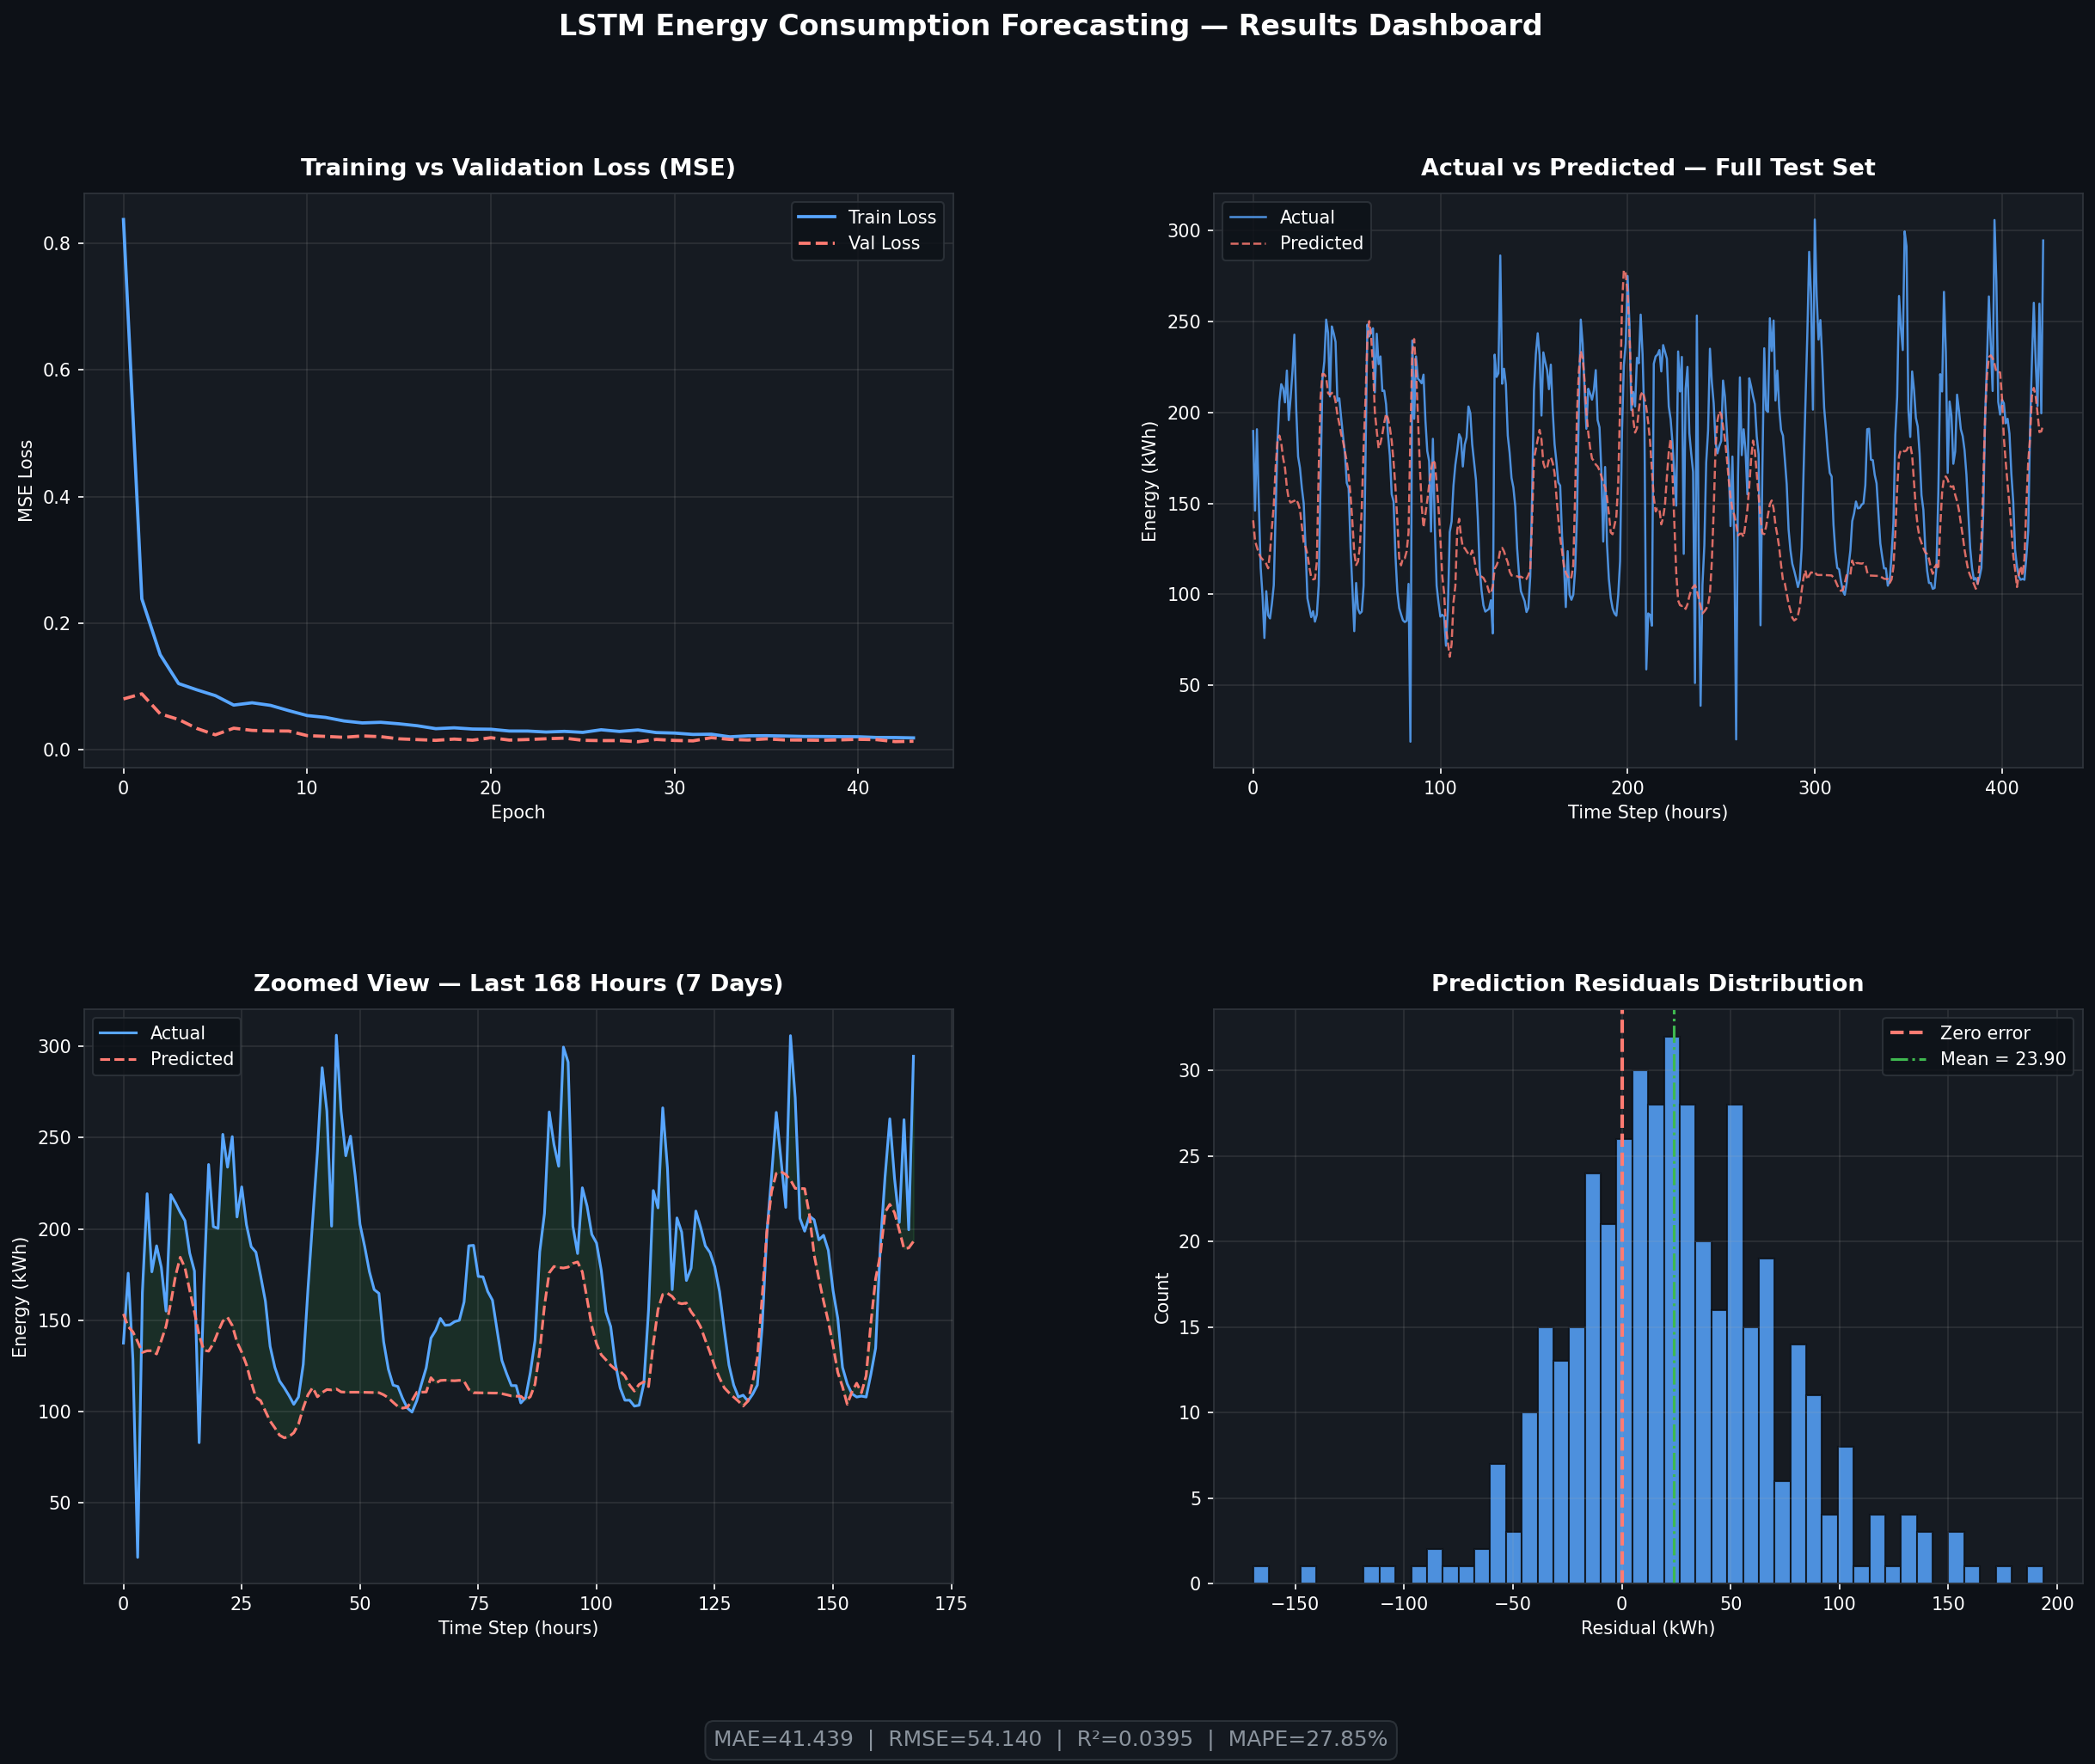

In [19]:
plot_results(history, y_true, y_pred, metrics, CONFIG["plot_path"])

# Display the saved plot inline
from IPython.display import Image
Image(CONFIG["plot_path"])

## Pipeline Summary

In [20]:
print("\n" + "=" * 65)
print("  PIPELINE COMPLETE")
print(f"  Best model saved → {CONFIG['model_path']}")
print(f"  Plots saved      → {CONFIG['plot_path']}")
print("=" * 65)

print("\nFinal Metrics:")
for k, v in metrics.items():
    print(f"  {k}: {v:.4f}")


  PIPELINE COMPLETE
  Best model saved → best_lstm_model.keras
  Plots saved      → lstm_results.png

Final Metrics:
  MAE: 41.4389
  RMSE: 54.1396
  R2: 0.0395
  MAPE: 27.8467
